# ToDo MVP:
- Importing data 

- Defining classes ( try only with Strong PYT && Decoy 1 / Decoy 7)
- Define model 

- Define Loss
- Defin minimization algorithm 
- Fit

- Inspect expected trends
- Visualize results (comparison)

In [1]:
# Standard libraries used throughout the notebook
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats
import seaborn as sns
import itertools
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import math

import warnings
from scipy.optimize import minimize

from sklearn.model_selection import train_test_split

# Personal libraries 

import model_database as db
import simulation_core as sim
import fitting_core as fit

# To use directely module variation
%load_ext autoreload
%autoreload 2


## Import data

In [2]:
# Standard libraries used throughout the notebook
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats
import seaborn as sns
import itertools
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import math


# --------------------------------------------------------------------------
# PATH_DATASET uploading 
# --------------------------------------------------------------------------

# first normalization method
PATH_RAW_DATASET = r"C:\Users\marco\Desktop\Tesi + Laurea\.LabWork\Data\Data from Suzanne\fitness_calc_PB_H3B.xlsx"
PATH_LOG_READS_NORMALIZED = r"C:/Users/marco/Desktop/Tesi + Laurea/.LabWork/Results/log_reads_norm.csv"
PATH_LFC = "C:/Users/marco/Desktop/Tesi + Laurea/.LabWork/Results/lfc_results.csv"

# secondth normalization method
path_H = r"C:\Users\marco\Desktop\Tesi + Laurea\.LabWork\Code\4. Data Transformation\normalized_matrix_H.csv"
path_PB = r"C:\Users\marco\Desktop\Tesi + Laurea\.LabWork\Code\4. Data Transformation\normalized_matrix_PB.csv"

# We load the raw file with no changes.
# data_raw will never be modified — it stays as the original reference.
data_raw = pd.read_excel(PATH_RAW_DATASET)
data_reads_norm = pd.read_csv(PATH_LOG_READS_NORMALIZED)
data_lfc = pd.read_csv(PATH_LFC)

data_reads_norm.columns = data_reads_norm.columns.str.replace(
    "output_", "norm_reads_", regex=False
)

data_lfc.drop(columns=["DECOY", "PYT", "ANCHOR"], inplace=True)

data_H_new = pd.read_csv(path_H)
data_PB_new = pd.read_csv(path_PB)

df_unito = pd.merge(data_H_new, data_PB_new, on='seq_id', how='inner')
df_unito.drop('norm_Control_y', axis=1, inplace=True)
df_unito.rename(columns={'norm_Control_x': 'norm_Control'}, inplace=True)
df_unito.columns = df_unito.columns.str.replace(
    "norm_", "new_norm_reads_", regex=False
)

# --------------------------------------------------------------------------
# Data Merging ( unify the datasets)
# --------------------------------------------------------------------------
df_CLR_norm = pd.merge(data_reads_norm, data_lfc, on="seq_id")
df_CLR_norm['seq_id'] = df_CLR_norm['seq_id'].astype(int)
data = pd.merge(data_raw, df_CLR_norm, on="seq_id")
data = pd.merge(data, df_unito, on="seq_id")


# --------------------------------------------------------------------------
# Data Filtering
# --------------------------------------------------------------------------

MIN_READS_THRESHOLD = 20

n_total   = len(data_raw)
mask_ok   = data["Input_counts"] >= MIN_READS_THRESHOLD
n_removed = (~mask_ok).sum()
n_kept    = mask_ok.sum()

data_filtered = data[mask_ok].copy().reset_index(drop=True)
data_filtered['ANCHOR'] = data_filtered['ANCHOR'].astype(str)

# --------------------------------------------------------------------------
# addign the new normalization lfc method 
# --------------------------------------------------------------------------


numeri_pb = [1, 2, 4, 8]

# Costante per evitare log(0) o divisioni per 0 (pseudocount standard = 1)
pseudocount = 1

for num in numeri_pb:
    col_trattata = f'new_norm_reads_PB{num}'
    col_controllo = 'new_norm_reads_Control'
    nuova_colonna = f'new_lfc_PB{num}'
    
    # Calcolo del Log2 Fold Change con pseudocount
    data_filtered[nuova_colonna] = np.log2(
        (data_filtered[col_trattata] + pseudocount) / (data_filtered[col_controllo] + pseudocount)
    )

numeri_h3b = [1, 2, 3, 4, 5]

# Costante per evitare log(0) o divisioni per 0 (pseudocount standard = 1)
pseudocount = 1

for num in numeri_h3b:
    col_trattata = f'new_norm_reads_H{num}'
    col_controllo = 'new_norm_reads_Control'
    nuova_colonna = f'new_lfc_H3B{num}'
    
    # Calcolo del Log2 Fold Change con pseudocount
    data_filtered[nuova_colonna] = np.log2(
        (data_filtered[col_trattata] + pseudocount) / (data_filtered[col_controllo] + pseudocount)
    )

# --------------------------------------------------------------------------
# Adding the BP feature 
# --------------------------------------------------------------------------

def filter_sequence(sequence: str, to_find: str) -> str:
    """Optimizes the input sequence for the SVM finder by removing the final

    section that follows the specified sub-string (e.g., 'CAG').

    Parameters:
        - sequence: str, the string to be cut
        - to_find: str, the sub-string to locate

    Returns:
        - str: The subsetted string, including the 'to_find' sequence at the
        end.
    Raise:
        - ValueError if the to_find string isn't in the sequence
    """
    # Find the index of the last occurrence (searching from right to left)
    idx = sequence.rfind(to_find)

    # If the sub-string is not found, rfind returns -1.
    if idx == -1:
    # In this case, we return the original sequence.
        raise ValueError(f"The string {to_find} is not in {sequence}.")

    # Slice the string to keep everything from the beginning
    # up to the end of 'to_find' (inclusive)
    return sequence[: idx + len(to_find)]

def BP_extractor(data):
    final_str = 'CAG'
    linker = 'GCG'
    strong_pyt = 'UUUUUCUUUUCUUUU'.replace('U', 'T')
    
    suffix_len = len(linker + strong_pyt + final_str)  # 21nt
    
    return data['full_seq'].apply(lambda seq: seq[-(suffix_len+7):-suffix_len])



pattern = 'CAG'

data_filtered['full_seq'] = data_filtered['full_seq'].apply(
    lambda seq: filter_sequence(seq, pattern)
)

data_filtered['BP_extracted'] = BP_extractor(data_filtered)


focus_sub_data = data_filtered[(data_filtered['DECOY'] == 'Decoy 7') & (data_filtered['PYT'] == 'Strong')]
data_filtered['BP_extracted'] = BP_extractor(data_filtered)

focus_sub_data = data_filtered[(data_filtered['DECOY'] == 'Decoy 7') & (data_filtered['PYT'] == 'Strong')]

# 1. Compute mean normalized reads per unique BP — reference condition only
bp_distribution = focus_sub_data.groupby('BP_extracted')['norm_reads_Ctrl'].mean()

# 2. Sort from highest to lowest
bp_ranked = bp_distribution.sort_values(ascending=False)

ranked_values = bp_ranked.values
ranked_categories = bp_ranked.index.tolist()

# 3. Rank-based quartile cuts
total_unique_bps = len(ranked_categories)
cut_strong       = int(total_unique_bps * 0.25)
cut_intermediate = int(total_unique_bps * 0.75)

strong_bp_names       = set(ranked_categories[:cut_strong])
intermediate_bp_names = set(ranked_categories[cut_strong:cut_intermediate])
weak_bp_names         = set(ranked_categories[cut_intermediate:])

# 4. Assign class to the full dataset
conditions = [
    data_filtered['BP_extracted'].isin(strong_bp_names),
    data_filtered['BP_extracted'].isin(intermediate_bp_names),
    data_filtered['BP_extracted'].isin(weak_bp_names)
]
choices = ['BP_Strong', 'BP_Intermediate', 'BP_Weak']

data_filtered['BP_class'] = np.select(conditions, choices, default='Unknown')



# --------------------------------------------------------------------------
# LFC old and new normalization PB
# --------------------------------------------------------------------------
lfc = [col for col in data_filtered.columns if 'lfc' in col]            # old normalization 
lfc_new = [col for col in data_filtered.columns if 'new_lfc_P' in col]    # new normalization 

# --------------------------------------------------------------------------
# LFC for H3B norm
# --------------------------------------------------------------------------
lfc_h3b = [col for col in data_filtered.columns if 'new_lfc_H' in col]            # old normalization 





# --------------------------------------------------------------------------
# Stratification of classes (BP_class x DECOY x PYT) (PladB)
# --------------------------------------------------------------------------

variables = ['BP_class', 'DECOY', 'PYT']
normalized = [col for col in data_filtered.columns if 'norm_reads' in col]

focus_cols = ['seq_id', *variables, *lfc_new,]                          # using new lfc
df_lfc = data_filtered.loc[:, focus_cols]




unique_values = [df_lfc[col].dropna().unique() for col in variables]
combinations_names = list(itertools.product(*unique_values))

stratified_data =  {}
for key_classes, subset in df_lfc.groupby(variables):
    stratified_data[key_classes] = subset.drop(
        columns = variables
    )

# --------------------------------------------------------------------------
# Stratification of classes (BP_class x DECOY x PYT) (H3B)
# --------------------------------------------------------------------------

variables = ['BP_class', 'DECOY', 'PYT']
normalized = [col for col in data_filtered.columns if 'norm_reads' in col]

focus_cols = ['seq_id', *variables, *lfc_h3b,]                          # using h3b
df_lfc = data_filtered.loc[:, focus_cols]




unique_values = [df_lfc[col].dropna().unique() for col in variables]
combinations_names = list(itertools.product(*unique_values))

stratified_data_h3b =  {}
for key_classes, subset in df_lfc.groupby(variables):
    stratified_data_h3b[key_classes] = subset.drop(
        columns = variables
    )



# --------------------------------------------------------------------------
# CONSTANT definition
# --------------------------------------------------------------------------
DRUG_CONCENTRATIONS_raw = [1e-11, 1e-10, 2e-10, 4e-10, 1e-09]
def scale_drug_concentration(drug_linear, 
                             min_real=1e-11, 
                             max_real=1e-9, 
                             min_scaled=0., 
                             max_scaled=100.0):
    """
    Scala la concentrazione lineare del farmaco in un range lineare personalizzato (es. 1-100)
    passando prima per lo spazio logaritmico, per preservare la sensibilità alle basse dosi.
    """
    # 1. Passaggio allo spazio logaritmico (esponenti)
    log_drug = np.log10(drug_linear)
    log_min = np.log10(min_real)  # -11
    log_max = np.log10(max_real)  # -9
    
    # 2. Traslazione e riscalamento lineare dell'esponente nel nuovo range [min_scaled, max_scaled]
    drug_scaled = min_scaled + (log_drug - log_min) * (max_scaled - min_scaled) / (log_max - log_min)
    
    return drug_scaled

DRUG_CONCENTRATIONS = scale_drug_concentration(DRUG_CONCENTRATIONS_raw)

DRUG_CONCENTRATIONS_raw_h3b = [1e-11, 1e-10, 1e-9, 1e-8, 1e-07, 1e-06]
DRUG_CONCENTRATIONS_h3b = scale_drug_concentration(DRUG_CONCENTRATIONS_raw_h3b)

# Model selection

In [3]:
model_4 = 'k3[linear_decrease]__4nodes'

## Select Desired data (select decoyz!!!!)

As first approximation we'll select:

- PYT _strong_ (seems to be the best responsive element)
- BP strenght: _Strong or Weak_ ( to look only at extreme values )
- Decoy: _*No Decoy & Max Decoy*_

In [4]:
#===========================================================================================
# Plad B
#===========================================================================================

desired_classes = {
    k: v
    for k, v in stratified_data.items()
    if "BP_Intermediate" not in k 
    and "Weak" not in k 
    and "Unknown" not in k 
    and ('Decoy 7' in k or 'Decoy 1' in k)
}
random_class = ('BP_Strong', 'Decoy 1', 'Strong')
sequences_number = desired_classes[random_class].shape[0] * len(desired_classes.keys())
print(f"The analysis will focus on approximatively n = {sequences_number} sequences....")



# List extraction
class_names  = [f"{k[0]}_{k[1]}_PYT_{k[2]}" for k in desired_classes.keys()]
classes_data = list(desired_classes.values())

#===========================================================================================
# H3b
#===========================================================================================
desired_classes_h3b = {
    k: v
    for k, v in stratified_data_h3b.items()
    if "BP_Intermediate" not in k 
    and "Weak" not in k 
    and "Unknown" not in k 
    and ('Decoy 7' in k or 'Decoy 1' in k)
}

random_class_h3b = ('BP_Strong', 'Decoy 1', 'Strong')
sequences_number_h3b = desired_classes_h3b[random_class_h3b].shape[0] * len(desired_classes_h3b.keys())
print(f"The analysis will focus on approximatively n = {sequences_number_h3b} sequences....")

class_names_h3b  = [f"{k[0]}_{k[1]}_PYT_{k[2]}" for k in desired_classes_h3b.keys()]
classes_data_h3b = list(desired_classes_h3b.values())




The analysis will focus on approximatively n = 7860 sequences....
The analysis will focus on approximatively n = 7860 sequences....


### Train - Test split  ( not necessary)

# Simulation Running.... Plad B (giu trovi H3B)

In [ ]:
n_start = 70
fixed_params_PB = {'k1': 1., 'k2': 1. }

best_fit, fit_history, fit_dictionary = fit.multistart_fit_multiclass(
    classes_data       = classes_data,
    class_names        = class_names,
    shared_param_names = ['k_1', 'k_2', 'k3', 'k4','alpha'],
    drug_conc          = DRUG_CONCENTRATIONS[1:],
    model_name         = model_4,
    fixed_params       = fixed_params_PB,
    n_starts           = n_start, 
    log_bounds         = (-5, 5),
    show_history       = True, 
    show_messages      = True,
    show_dict          = True,
)


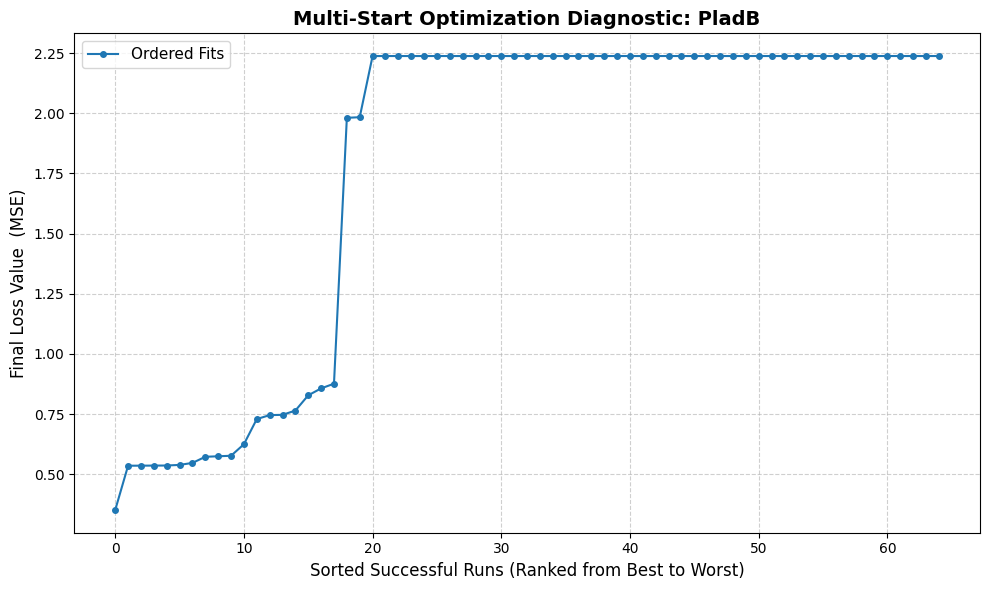

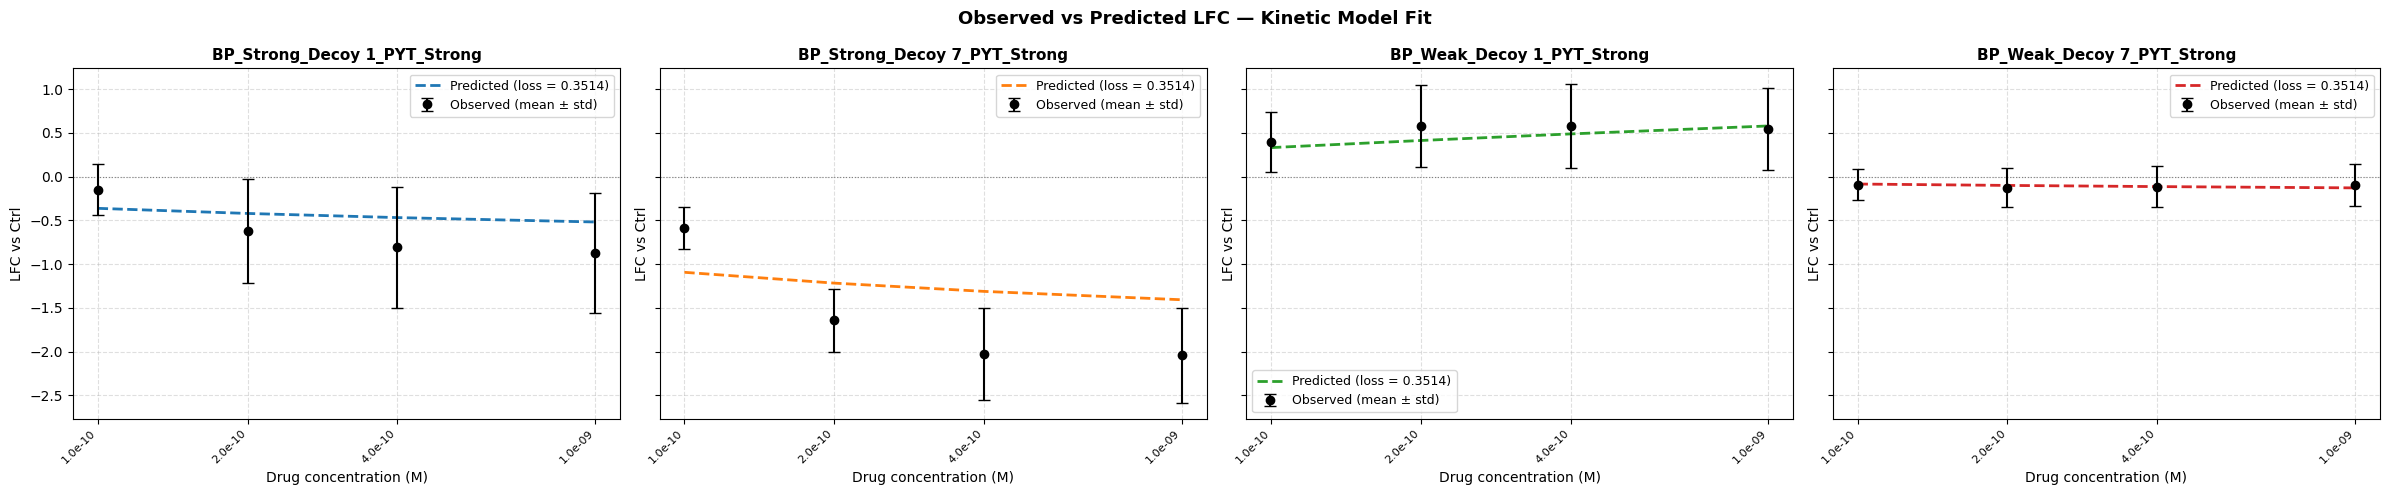

In [19]:
fit.plot_optimization_diagnostic(fit_history, 'PladB')
fit.plot_fit_comparison_multiclass(
    classes_data       = classes_data,
    classes_names      = class_names,
    best_fit           = best_fit,
    fit_dict           = fit_dictionary,
    drug_conc          = DRUG_CONCENTRATIONS[1:],        
    real_concentrations= DRUG_CONCENTRATIONS_raw[1:],    
    model_name         = model_4,
    fixed_params       = fixed_params_PB
)

# Running Simulation..... H3B <<<<<<----------------

In [ ]:
n_start = 70
fixed_params = {'k1': 1., 'k2': 1.}

best_fit_h3b, fit_history_h3b, fit_dictionary_h3b = fit.multistart_fit_multiclass(
    classes_data       = classes_data_h3b,
    class_names        = class_names_h3b,
    shared_param_names = ['k_1', 'k_2', 'k3', 'k4','alpha'],
    drug_conc          = DRUG_CONCENTRATIONS_h3b[1:],
    model_name         = model_4,
    fixed_params       = fixed_params,
    n_starts           = n_start, 
    log_bounds         = (-5, 5),
    show_history       = True, 
    show_messages      = True,
    show_dict          = True,
)




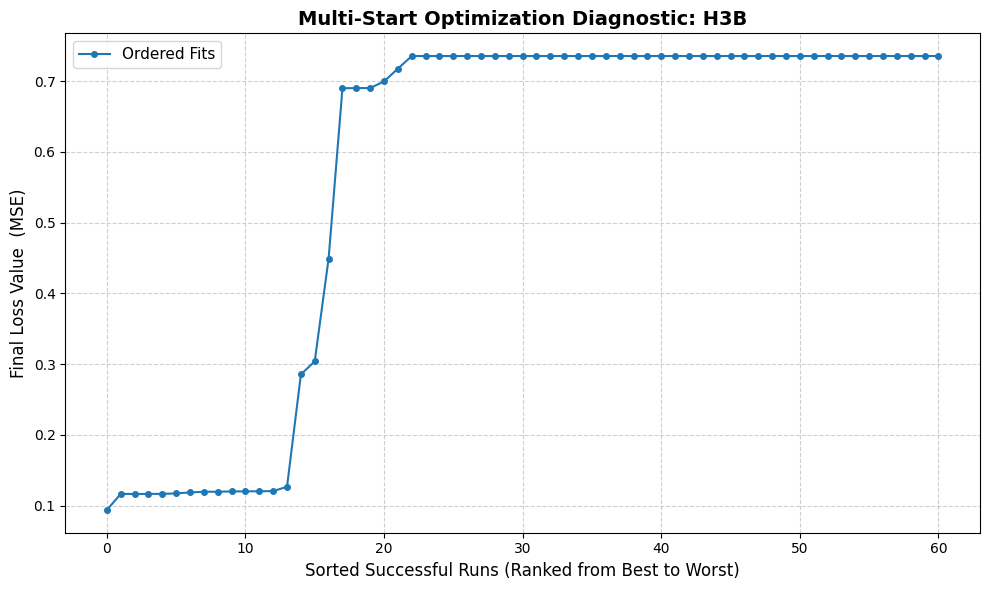

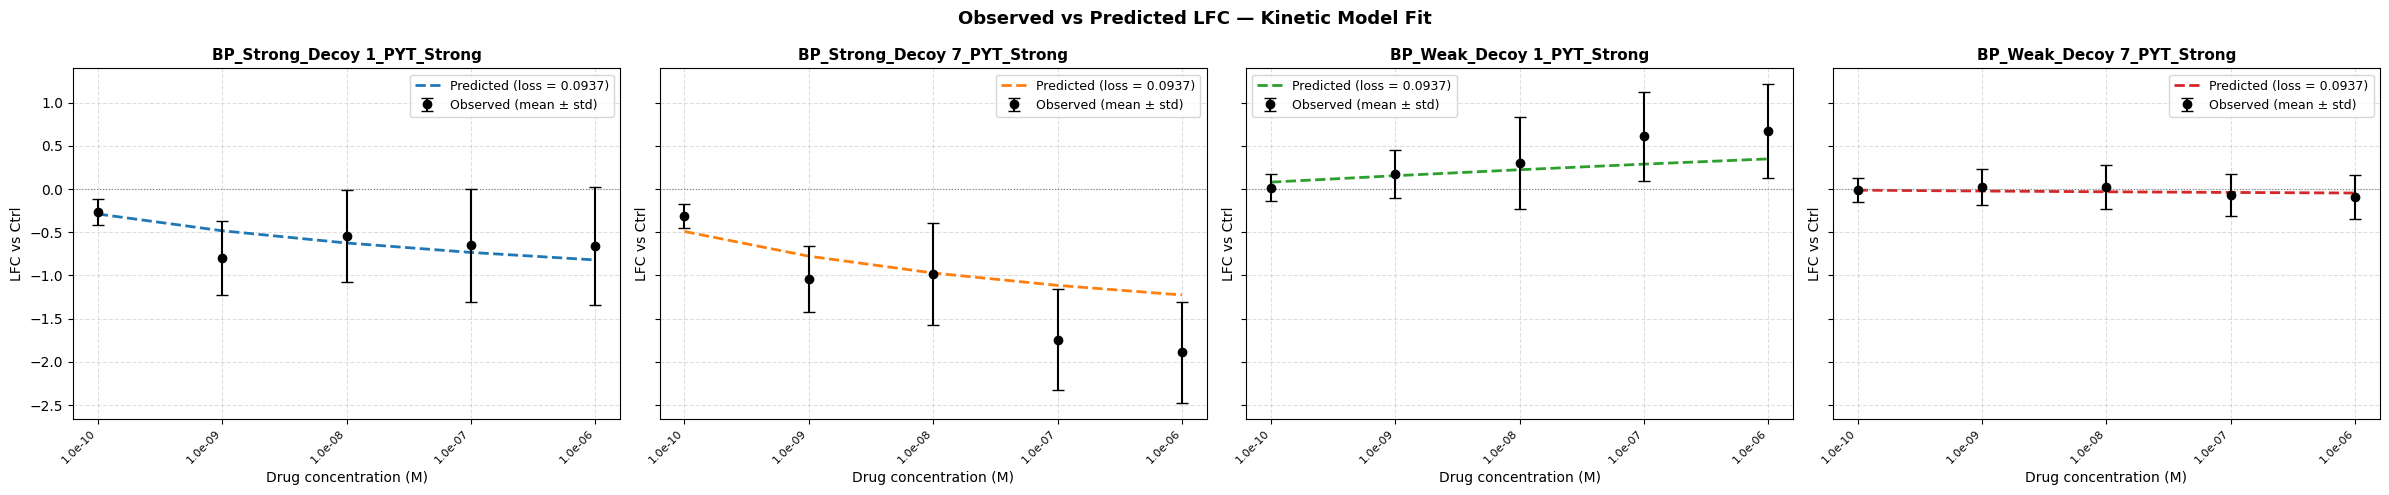

In [18]:
fit.plot_optimization_diagnostic(fit_history_h3b , 'H3B')
fit.plot_fit_comparison_multiclass(
    classes_data       = classes_data_h3b,
    classes_names      = class_names_h3b,
    best_fit           = best_fit_h3b,
    fit_dict           = fit_dictionary_h3b,
    drug_conc          = DRUG_CONCENTRATIONS_h3b[1:],        
    real_concentrations= DRUG_CONCENTRATIONS_raw_h3b[1:],    
    model_name         = model_4,
    fixed_params       = {'k1': 1., 'k2': 1.}
)

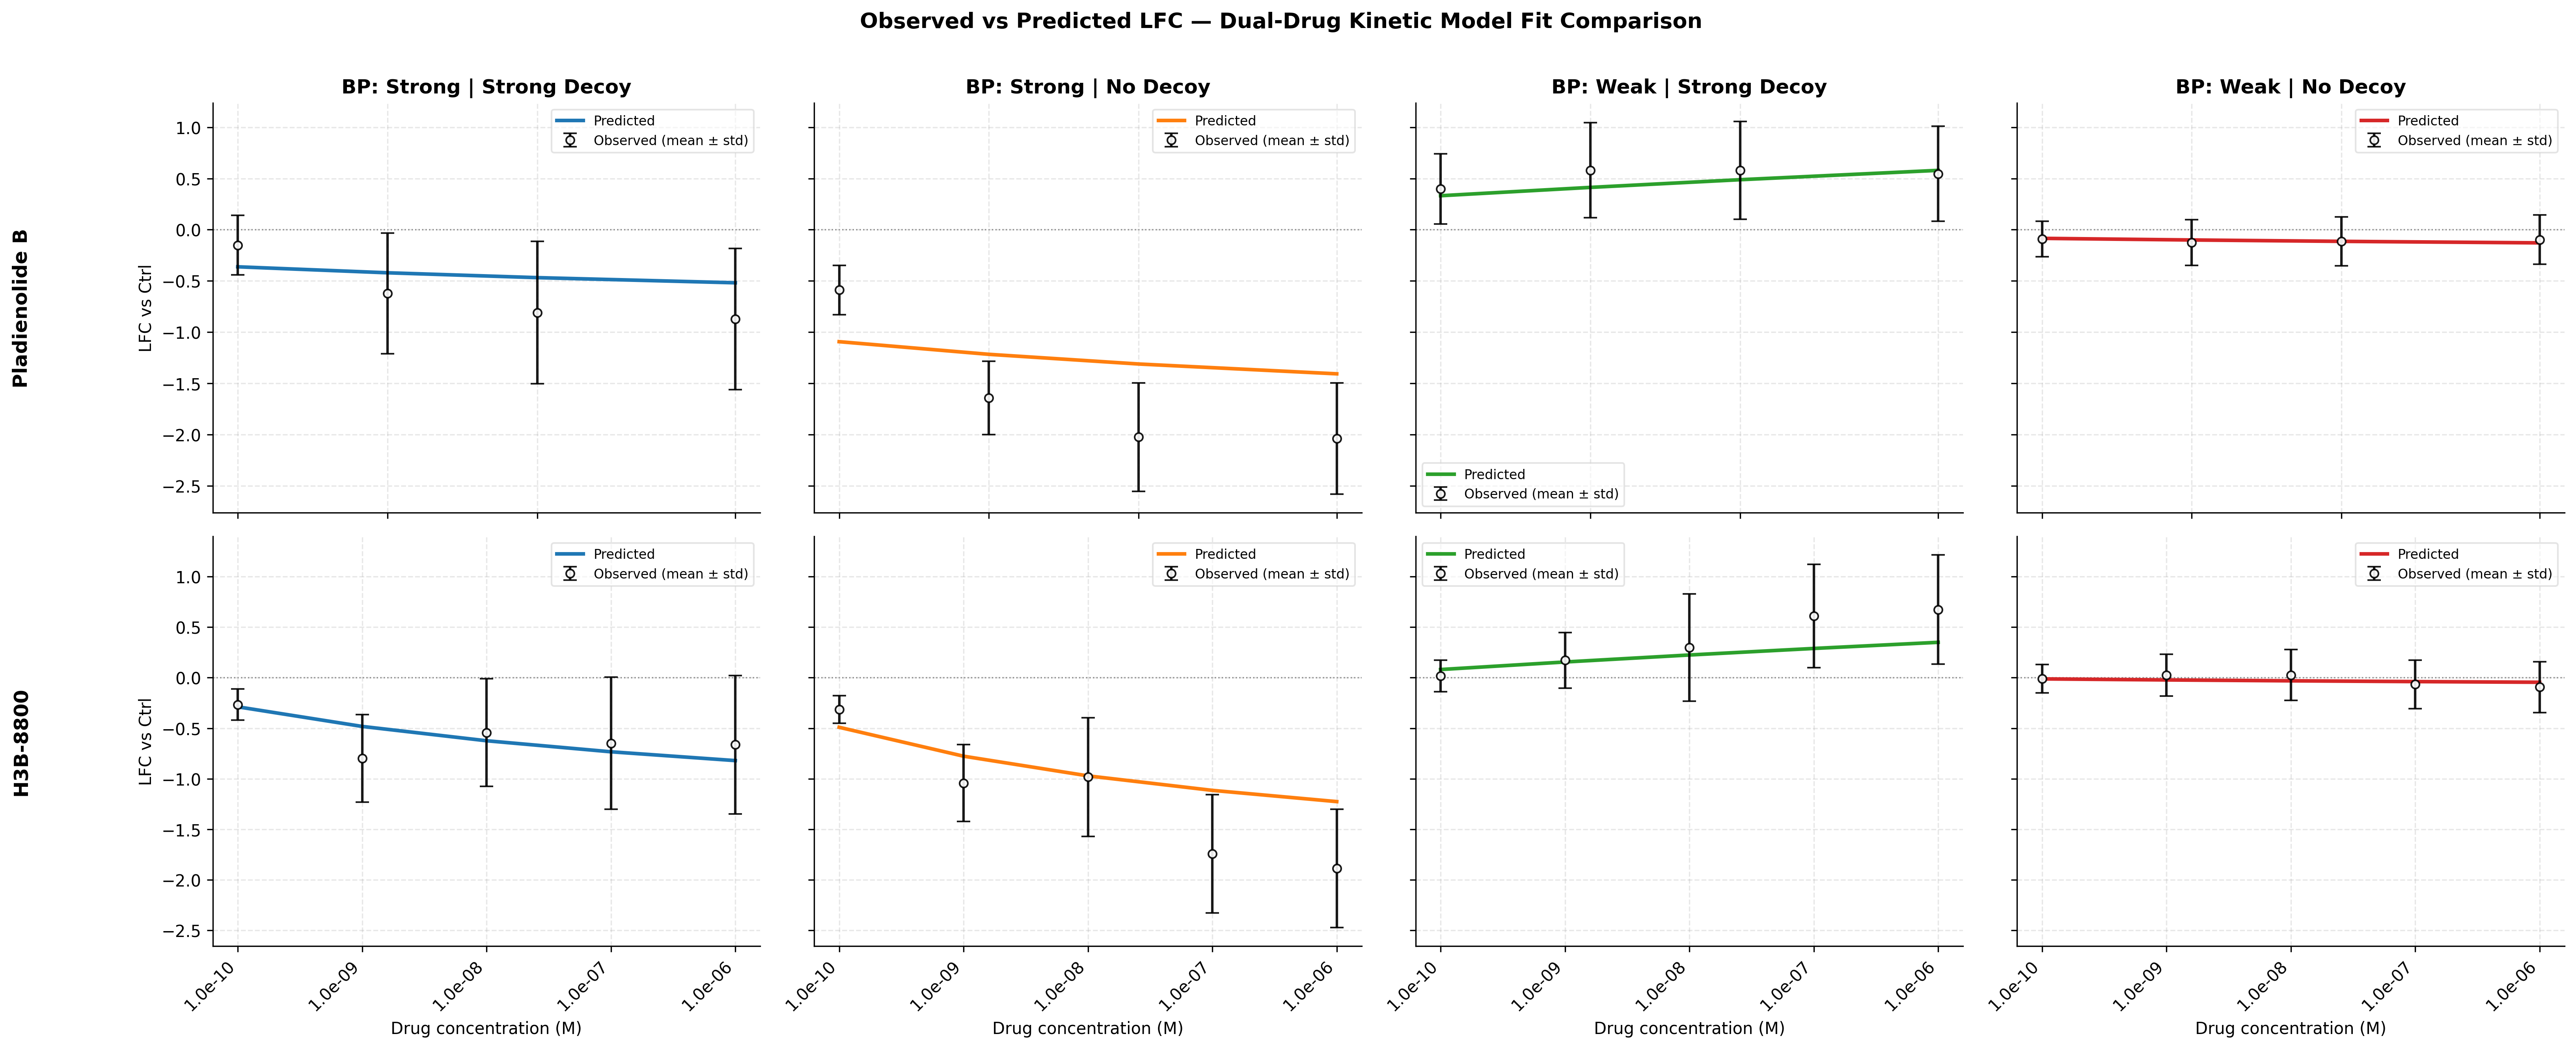

In [23]:
import importlib
importlib.reload(fit)
fit_results_PB = {
    'best_fit': best_fit,
    'fit_dict': fit_dictionary
}

fit_results_H3B = {
    'best_fit': best_fit_h3b,
    'fit_dict': fit_dictionary_h3b
}

fit.plot_dual_drug_fit_comparison(
    classes_data_1        = classes_data,
    classes_data_2        = classes_data_h3b,
    classes_names         = class_names,
    drug_conc_1           = DRUG_CONCENTRATIONS[1:],
    real_concentrations_1 = DRUG_CONCENTRATIONS_raw[1:],
    drug_conc_2           = DRUG_CONCENTRATIONS_h3b[1:],
    real_concentrations_2 = DRUG_CONCENTRATIONS_raw_h3b[1:],
    model_name            = model_4,
    fit_results_drugA     = fit_results_PB,
    fit_results_drugB     = fit_results_H3B,
    drug_name_1           = "Pladienolide B",
    drug_name_2           = "H3B-8800",
    fixed_params          = fixed_params_PB,
    dpi                   = 300
)